<div style="background-color:#e6f0ff; padding:15px; border-radius:10px;">

<h2>Estimación de la Curva de Phillips para España</h2>

En esta práctica estudiamos la relación a medio plazo entre la inflación y la tasa de paro en la economía española mediante la estimación empírica de una <b>Curva de Phillips</b>. Para ello utilizamos datos trimestrales procedentes de la base de datos BDREMS:
<ul>
  <li><b>Tasa de paro trimestral</b> de España.</li>
  <li><b>Deflactor del gasto en consumo final de los Hogares + ISFSH</b>, también trimestral.</li>
</ul>

A partir del deflactor de consumo construiremos la <b>inflación anual</b> como tasa de crecimiento logarítmica a cuatro trimestres:

$$
\pi_t = 100 \cdot [\ln(P_t) - \ln(P_{t-4})].
$$

Supondremos además un mecanismo de <b>expectativas adaptativas</b>, de modo que la inflación esperada dentro de un año es la inflación observada hoy:

$$
\pi_{t+4}^e = \pi_t.
$$

Bajo esta hipótesis, la Curva de Phillips se expresa como:

$$
\Delta_4 \pi_t = \beta_0 + \beta_1 u_t + \varepsilon_t,
$$

donde evaluamos:
<ul>
  <li>Variación anual de la inflación.</li>
  <li>Tasa de paro.</li>
</ul>

El objetivo principal es:
<ul>
  <li><b>estimar la tasa natural de paro</b> </li>
  <li><b>calcular su desviación típica</b> mediante el método Delta,</li>
  <li>y extender posteriormente el análisis para considerar <b>distintos regímenes de inflación</b>.</li>
</ul>

</div>




In [99]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")


In [100]:
fuente = "datos_phillips.xlsx"
df = pd.read_excel(fuente)

# Comprobar columnas
print(df.columns)

# Construimos una fecha aproximada: primer mes de cada trimestre
# (T1 -> marzo, T2 -> junio, T3 -> septiembre, T4 -> diciembre)
mes = df['trimestre'] * 3
df['fecha'] = pd.to_datetime(
    dict(year=df['anio'], month=mes, day=1)
)

# Ordenar por fecha
df = df.sort_values(['anio', 'trimestre']).reset_index(drop=True)

df.head()



Index(['anio', 'trimestre', 'precio', 'tasa_paro', 'log ', 'pi_t',
       'delta4_pi'],
      dtype='object')


,anio,trimestre,precio,tasa_paro,log,pi_t,delta4_pi,fecha
0,1980,1,0.177322,9.706395,-1.729789,NaN,NaN,1980-03-01
1,1980,2,0.195594,10.425212,-1.631714,NaN,NaN,1980-06-01
2,1980,3,0.210145,10.904520,-1.559956,NaN,NaN,1980-09-01
3,1980,4,0.218290,11.540145,-1.521930,NaN,NaN,1980-12-01
4,1981,1,0.198868,12.168170,-1.615115,11.467486,NaN,1981-03-01


<div style="background-color:#f4f9ff; padding:15px; border-radius:10px;">

<h3>Parte 1: Estimación de la tasa natural de paro (ū) con toda la muestra</h3>

En esta primera parte utilizaremos todos los datos disponibles en BDREMS para estimar una Curva de Phillips simple basada en expectativas adaptativas. La ecuación a estimar es:

$$
\Delta_4 \pi_t = \beta_0 + \beta_1 u_t + \varepsilon_t.
$$

A partir de la teoría de la Curva de Phillips con expectativas, existe una relación entre los parámetros estimados y la <b>tasa natural de paro</b>:

$$
\beta_0 = \alpha \bar{u}, 
\qquad 
\beta_1 = -\alpha.
$$

Por tanto, el estimador es:

$$
\hat{\bar{u}} = -\frac{\hat{\beta}_0}{\hat{\beta}_1}.
$$

Para evaluar la precisión de esta estimación, calcularemos la <b>desviación típica</b> de \(\hat{\bar{u}}\) aplicando el <b>método Delta</b>, utilizando el gradiente de la función no lineal:

$$
f(\beta_0, \beta_1) = -\frac{\beta_0}{\beta_1}.
$$

y la matriz de varianzas-covarianzas.

Al finalizar esta parte habremos obtenido:
<ul>
  <li>La estimación puntual de la tasa de paro natural.</li>
  <li>Su desviación típica y, opcionalmente, un intervalo de confianza.</li>
</ul>

</div>


In [101]:
# Logaritmo del precio
df['log_P'] = np.log(df['precio'])

# Inflación anual ln(π_t) = ln(P_t) - ln(P_{t-4}*100)
df['pi_t'] = (df['log_P'] - df['log_P'].shift(4)) *100

# Δ4π_t = π_t - π_{t-4}
df['delta4_pi'] = df['pi_t'] - df['pi_t'].shift(4)

# Eliminamos observaciones iniciales sin datos completos
df_model = df.dropna(subset=['delta4_pi', 'tasa_paro']).copy()

df_model[['log_P','fecha', 'tasa_paro', 'pi_t', 'delta4_pi']].head()



,log_P,fecha,tasa_paro,pi_t,delta4_pi
8,-1.466049,1982-03-01,14.035329,14.906513,3.439027
9,-1.363573,1982-06-01,14.309347,13.762080,0.710053
10,-1.304598,1982-09-01,14.987015,12.044711,-1.446437
11,-1.262152,1982-12-01,15.318076,12.053207,-1.871354
12,-1.349363,1983-03-01,15.613193,11.668625,-3.237888


In [102]:
Y = df_model['delta4_pi']            # Δ4π_t
X = df_model[['tasa_paro']]          # u_t
X = sm.add_constant(X)               # añade intercepto β0

model1 = sm.OLS(Y, X)
res1 = model1.fit()

print(res1.summary())


                            OLS Regression Results                            
Dep. Variable:              delta4_pi   R-squared:                       0.029
Model:                            OLS   Adj. R-squared:                  0.023
Method:                 Least Squares   F-statistic:                     4.952
Date:                Mon, 17 Nov 2025   Prob (F-statistic):             0.0274
Time:                        16:41:40   Log-Likelihood:                -358.22
No. Observations:                 167   AIC:                             720.4
Df Residuals:                     165   BIC:                             726.7
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.1129      0.616      1.807      0.0

In [103]:
b_hat = res1.params
b0_hat = b_hat['const']
b1_hat = b_hat['tasa_paro']

u_bar_hat = - b0_hat / b1_hat
print(f"(ū̂) = {u_bar_hat:.4f}")



(ū̂) = 13.3589


In [104]:
# Matriz de covarianzas de (β0, β1)
cov_beta1 = res1.cov_params().loc[['const', 'tasa_paro'], ['const', 'tasa_paro']]

# Gradiente de f(β0, β1) = -β0/β1
g1 = -1.0 / b1_hat
g2 = b0_hat / (b1_hat**2)
G = np.array([[g1],
              [g2]])  # 2x1

Sigma1 = cov_beta1.to_numpy()

var_u_bar_hat = float(G.T @ Sigma1 @ G)
std_u_bar_hat = np.sqrt(var_u_bar_hat)

print(f"Varianza(ū̂) ≈ {var_u_bar_hat:.6f}")
print(f"Desviación típica(ū̂) ≈ {std_u_bar_hat:.6f}")



Varianza(ū̂) ≈ 5.017798
Desviación típica(ū̂) ≈ 2.240044


/var/folders/tk/lzgzrvjs12n47rkb247_bbnm0000gn/T/ipykernel_87072/1893832733.py:12: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  var_u_bar_hat = float(G.T @ Sigma1 @ G)


In [105]:
z = 1.96
lower = u_bar_hat - z * std_u_bar_hat
upper = u_bar_hat + z * std_u_bar_hat

print(f"IC 95% (ū̂): [{lower:.4f}, {upper:.4f}]")


IC 95% (ū̂): [8.9684, 17.7494]


<div style="background-color:#f4fffa; padding:15px; border-radius:10px;">

<h3>Parte 2: Curva de Phillips con regímenes de inflación alta y baja</h3>

En esta segunda parte exploraremos si la relación entre inflación y paro cambia dependiendo del nivel de inflación observado. Para ello dividiremos la muestra en dos regímenes:

<ul>
  <li><b>Inflación alta</b>: \(\pi_t > 4\%\)</li>
  <li><b>Inflación baja</b>: \(\pi_t \leq 4\%\)</li>
</ul>

Estimaremos una Curva de Phillips con <b>parámetros dependientes del régimen</b>:

$$
\Delta_4 \pi_t =
\beta_{01}\xi_t + \beta_{02}(1-\xi_t)
+ \beta_{11}\xi_t u_t + \beta_{12}(1-\xi_t)u_t
+ \varepsilon_t,
$$

donde \(\xi_t\) es una variable indicadora que vale 1 en periodos de inflación alta y 0 en periodos de inflación baja.

Esto nos permite obtener dos tasas naturales de paro:

$$
\bar{u}_1 = -\frac{\beta_{01}}{\beta_{11}}
\qquad\text{(inflación alta)},
$$

$$
\bar{u}_2 = -\frac{\beta_{02}}{\beta_{12}}
\qquad\text{(inflación baja)}.
$$

Al igual que en la Parte 1, calcularemos la <b>desviación típica</b> de cada estimación mediante el método Delta, usando las submatrices de la matriz de covarianzas asociadas a cada par \((\beta_{0j},\beta_{1j})\).

Finalmente evaluaremos si:
<ul>
  <li>La tasa natural de paro es distinta bajo inflación alta o baja.</li>
  <li>La relación inflación–paro es más o menos intensa en cada régimen.</li>
</ul>

</div>


In [106]:
# Dummy: 1 si inflación anual > 4%, 0 en caso contrario
df_model['xi'] = (df_model['pi_t'] > 4).astype(int)

# Regressors según el enunciado
df_model['one_minus_xi'] = 1 - df_model['xi']
df_model['xi_u'] = df_model['xi'] * df_model['tasa_paro']
df_model['one_minus_xi_u'] = df_model['one_minus_xi'] * df_model['tasa_paro']

Y2 = df_model['delta4_pi']

X2 = df_model[['xi', 'one_minus_xi', 'xi_u', 'one_minus_xi_u']]

X2.head()


,xi,one_minus_xi,xi_u,one_minus_xi_u
8,1,0,14.035329,0.0
9,1,0,14.309347,0.0
10,1,0,14.987015,0.0
11,1,0,15.318076,0.0
12,1,0,15.613193,0.0


In [107]:
model2 = sm.OLS(Y2, X2)
res2 = model2.fit()
print(res2.summary())


                            OLS Regression Results                            
Dep. Variable:              delta4_pi   R-squared:                       0.113
Model:                            OLS   Adj. R-squared:                  0.097
Method:                 Least Squares   F-statistic:                     6.924
Date:                Mon, 17 Nov 2025   Prob (F-statistic):           0.000205
Time:                        16:41:40   Log-Likelihood:                -350.67
No. Observations:                 167   AIC:                             709.3
Df Residuals:                     163   BIC:                             721.8
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
xi                 5.1343      1.249      4.

In [108]:
b2 = res2.params

beta01_hat = b2['xi']
beta02_hat = b2['one_minus_xi']
beta11_hat = b2['xi_u']
beta12_hat = b2['one_minus_xi_u']

u_bar1_hat = - beta01_hat / beta11_hat   # alta inflación
u_bar2_hat = - beta02_hat / beta12_hat   # baja inflación

print(f"ū1 (alta inflación)  = {u_bar1_hat:.4f}")
print(f"ū2 (baja inflación)  = {u_bar2_hat:.4f}")


ū1 (alta inflación)  = 16.4312
ū2 (baja inflación)  = -8.3993


In [109]:
cov_beta2 = res2.cov_params()

# Submatrices de covarianzas:
Sigma_high = cov_beta2.loc[['xi', 'xi_u'], ['xi', 'xi_u']]
Sigma_low  = cov_beta2.loc[['one_minus_xi', 'one_minus_xi_u'],
                           ['one_minus_xi', 'one_minus_xi_u']]

def delta_ratio(beta0, beta1, Sigma):
    """
    Devuelve (ū_hat, sd_ū_hat) para f(β0,β1) = -β0/β1
    usando método Delta.
    """
    g1 = -1.0 / beta1
    g2 = beta0 / (beta1**2)
    G = np.array([[g1],
                  [g2]])
    var = float(G.T @ Sigma.to_numpy() @ G)
    sd = np.sqrt(var)
    u_bar = - beta0 / beta1
    return u_bar, sd

u_bar1_hat, sd_u_bar1 = delta_ratio(beta01_hat, beta11_hat, Sigma_high)
u_bar2_hat, sd_u_bar2 = delta_ratio(beta02_hat, beta12_hat, Sigma_low)

print(f"ū1 alta inflación  = {u_bar1_hat:.4f}  (sd ≈ {sd_u_bar1:.4f})")
print(f"ū2 baja inflación  = {u_bar2_hat:.4f}  (sd ≈ {sd_u_bar2:.4f})")


ū1 alta inflación  = 16.4312  (sd ≈ 0.8009)
ū2 baja inflación  = -8.3993  (sd ≈ 52.5124)


/var/folders/tk/lzgzrvjs12n47rkb247_bbnm0000gn/T/ipykernel_87072/3033625873.py:17: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  var = float(G.T @ Sigma.to_numpy() @ G)


In [110]:
z = 1.96

ic1_lower = u_bar1_hat - z * sd_u_bar1
ic1_upper = u_bar1_hat + z * sd_u_bar1

ic2_lower = u_bar2_hat - z * sd_u_bar2
ic2_upper = u_bar2_hat + z * sd_u_bar2

print(f"IC 95% ū1 (alta inflación): [{ic1_lower:.4f}, {ic1_upper:.4f}]")
print(f"IC 95% ū2 (baja inflación): [{ic2_lower:.4f}, {ic2_upper:.4f}]")


IC 95% ū1 (alta inflación): [14.8615, 18.0009]
IC 95% ū2 (baja inflación): [-111.3236, 94.5251]


/Users/miguelfernandez/GitHub/ucm/venv_ucm/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8324 (\N{SUBSCRIPT FOUR}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


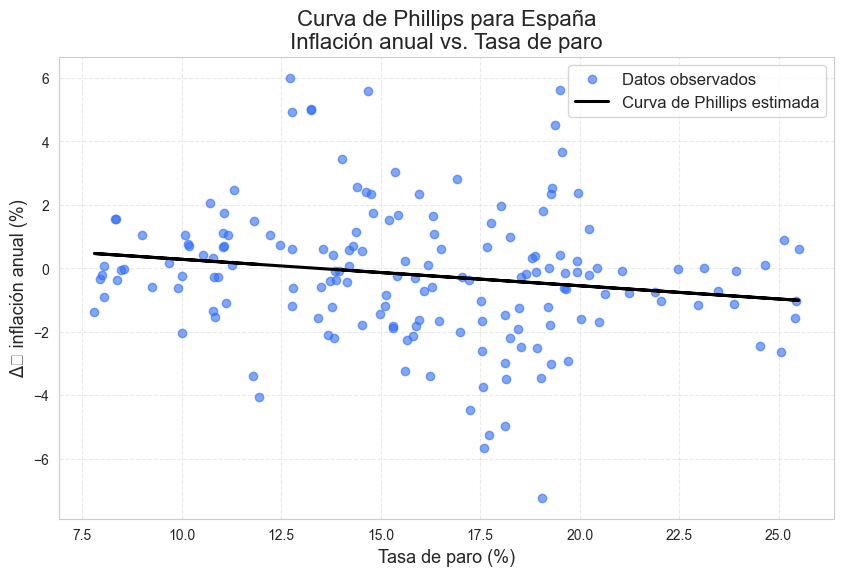

In [111]:
# Datos
x = df_model['tasa_paro']
y = df_model['delta4_pi']

# Ajustar recta de regresión para representarla visualmente
import numpy as np
X = sm.add_constant(x)
beta = np.linalg.lstsq(X, y, rcond=None)[0]  # estimadores OLS para la recta gráfica
recta = beta[0] + beta[1] * x

plt.figure(figsize=(10,6))

# Nube de puntos (scatter)
plt.scatter(x, y, alpha=0.6, color="#2f6df6", label="Datos observados")

# Recta ajustada
plt.plot(x, recta, color="black", linewidth=2.2, label="Curva de Phillips estimada")

# Detalles estéticos
plt.title("Curva de Phillips para España\nInflación anual vs. Tasa de paro", fontsize=16)
plt.xlabel("Tasa de paro (%)", fontsize=13)
plt.ylabel("Δ₄ inflación anual (%)", fontsize=13)
plt.legend(fontsize=12)
plt.grid(True, linestyle="--", alpha=0.4)

plt.show()


<div style="background-color:#fff8e6; padding:15px; border-radius:12px;">

<h2>Conclusiones del análisis de la Curva de Phillips para España</h2>

<h3>1. Modelo estimado y ajuste</h3>

Se ha estimado la siguiente Curva de Phillips con expectativas adaptativas:

$$
\Delta_4 \pi_t = \beta_0 + \beta_1 u_t + \varepsilon_t,
$$

donde \(\Delta_4 \pi_t\) es la variación anual de la inflación (deflactor del gasto en consumo de los hogares) y \(u_t\) es la tasa de paro trimestral.

El resultado de la regresión por MCO (167 observaciones) es:

<ul>
  <li><b>β̂₀ = 1.1129</b> (p = 0.073)</li>
  <li><b>β̂₁ = −0.0833</b> (p = 0.027)</li>
  <li><b>R² = 0.029</b></li>
</ul>

La pendiente negativa y significativa al 5% confirma una relación inversa entre paro y variación de la inflación, aunque el poder explicativo global del modelo (R² muy bajo) es reducido, algo habitual en Curvas de Phillips estimadas con datos macro trimestrales.

<hr>

<h3>2. Tasa de paro natural media (ū) para toda la muestra</h3>

A partir de la relación teórica \(\bar{u} = -\beta_0/\beta_1\), la tasa natural de paro estimada es:

<ul>
  <li><b>ū̂ = 13.36%</b></li>
  <li><b>Var(ū̂) ≈ 5.02</b></li>
  <li><b>sd(ū̂) ≈ 2.24</b></li>
  <li><b>IC 95%: [8.97%, 17.75%]</b></li>
</ul>

La media estimada se sitúa claramente en el terreno de dos dígitos, lo que es coherente con la evidencia histórica de elevados niveles estructurales de desempleo en la economía española. No obstante, el intervalo de confianza es amplio, reflejando una incertidumbre significativa en torno al valor exacto de \(\bar{u}\).

<hr>

<h3>3. Curva de Phillips por regímenes de inflación</h3>

Al distinguir entre periodos de <b>inflación alta</b> (\(\pi_t &gt; 4\%\)) e <b>inflación baja</b> (\(\pi_t \leq 4\%\)), se obtienen dos tasas naturales de paro:

<table style="border-collapse: collapse; width: 100%; text-align: left;">
  <thead style="background-color: #fbeedb;">
    <tr>
      <th style="padding: 8px; border-bottom: 2px solid #d9c9b1;">Régimen</th>
      <th style="padding: 8px; border-bottom: 2px solid #d9c9b1;">ū̂</th>
      <th style="padding: 8px; border-bottom: 2px solid #d9c9b1;">sd(ū̂)</th>
      <th style="padding: 8px; border-bottom: 2px solid #d9c9b1;">IC 95%</th>
      <th style="padding: 8px; border-bottom: 2px solid #d9c9b1;">Interpretación</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td><b>Inflación alta (πₜ &gt; 4%)</b></td>
      <td>16.43%</td>
      <td>0.80</td>
      <td>[14.86%, 18.00%]</td>
      <td>Estimación alta y bien identificada; la relación inflación–paro es fuerte en este régimen.</td>
    </tr>
    <tr>
      <td><b>Inflación baja (πₜ ≤ 4%)</b></td>
      <td>−8.40%</td>
      <td>52.51</td>
      <td>[−111.32%, 94.53%]</td>
      <td>Estimación prácticamente no informativa; el modelo no identifica una estimación clara con inflación baja.</td>
    </tr>
  </tbody>
</table>

La diferencia entre ambos resultados es muy clara:

<ul>
  <li>En <b>inflación alta</b> la Curva de Phillips es empíricamente nítida: la tasa natural estimada es elevada (≈16%) y el intervalo de confianza es relativamente estrecho.</li>
  <li>En <b>inflación baja</b> la enorme desviación típica y el intervalo de confianza desmesurado indican que el parámetro no está identificado: los datos no permiten extraer una estimación fiable en este régimen.</li>
</ul>

<hr>

<h3>4. Comentarios sobre los residuos y limitaciones</h3>

Los resultados del contraste de diagnóstico (Durbin–Watson &lt; 1, Jarque–Bera significativo, Omnibus significativo) apuntan a:

<ul>
  <li>Posible <b>autocorrelación positiva</b> en los residuos.</li>
  <li>Desviaciones respecto a la <b>normalidad</b>.</li>
</ul>

En un análisis más exhaustivo sería recomendable corregir estas deficiencias (por ejemplo, mediante errores estándar robustos tipo HAC o especificaciones dinámicas alternativas). No obstante, para los propósitos de esta práctica, el modelo proporciona una aproximación razonable a la relación media entre inflación y paro.

<hr>

<h3>5. Conclusión general</h3>

En conjunto, el ejercicio muestra que:

<ul>
  <li>Existe una <b>relación inversa</b> entre paro e inflación en España, consistente con la Curva de Phillips clásica.</li>
  <li>La <b> media</b> se sitúa en torno al <b>13–14%</b>, con un intervalo amplio pero claramente por encima de tasas de paro consideradas “bajas” en otros países europeos.</li>
  <li>En <b>entornos de inflación alta</b>, la Curva de Phillips se vuelve más pronunciada y la tasa natural estimada es aún mayor (≈16%), mientras que con inflación baja la relación se difumina y los parámetros dejan de estar bien identificados.</li>
</ul>

En el régimen de inflación alta $pi_t > 4$ obtenemos una tasa natural de paro $\bar{u}_1 \approx 16$, con un intervalo de confianza relativamente estrecho. En cambio, en el régimen de inflación baja la estimación de $\bar{u}_2$ es negativa y presenta una desviación típica muy elevada, lo que indica que el modelo no identifica una estimación fiable bajo baja inflación. Esto sugiere que la Curva de Phillips con expectativas adaptativas puede funcionar razonablemente bien cuando la inflación es alta, pero no describe adecuadamente la economía en escenarios de inflación baja y estable. En esos contextos, las expectativas parecen estar más ancladas en el objetivo del banco central que en la inflación pasada, por lo que sería necesario utilizar un mecanismo de formación de expectativas diferente —o dependiente del régimen— para capturar correctamente la relación entre inflación y paro.


</div>
